### Fitness Landscape Cómo Potencial de Selección Natural

---
En este cuaderno estudiaré, centrandose en un potencial de fitness a través de fitness landscape,fenómenos de selección sexual y su interacción con la selección natural. Consideraré dos fenotipos o estrategias, A y B. El fenotipo A tendrá mayor atractivo sexual y, por tanto, mayor éxito de apareamiento, mientras que el fenotipo B tendrá menor atractivo sexual pero también menor vulnerabilidad a los depredadores. Se va a trabajar a 3 niveles de profundización para abordar el primero. La primera sería un ftiness  constante e independiente de la frecuencia del fenotipo si se agregará algún parámetro lineal realizado con la saturación sexual. Luego, será un fitness dependiente de la frecuencia del fitness sin el parámetro adicional de 


Para cada nivel de profundización, se realizará un análisis de la matriz de pagos dónde se verán los casos de equilibrio luego se estudiará la ecuación del replicador, se realizará el proceso de Moran dónde se podrá hacer la comparativa con la ecuación del replicador debido a la estocasticidad. Luego, se realizarán 3 gráficas relacionadas con el fitness drift, el fitness promedio y la diferencia de fitness para cada población inicial de A y densidad de depredadores. Luego, se deberá construir un filtro para ver el comportamiento de las superficies. 


Aún está en proceso este cuaderno,
última fecha de edición : 16-nov-2026.

---


### Librerías
---

In [ ]:
import os
import time
import random
import numpy as np
import pandas as pd
from os import remove
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import plotly.graph_objects as go
from scipy.integrate import solve_ivp
from IPython.display import Image, display
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

---

#### Elementos Gráficos y Cod para Gráficas



---
### Matriz de Pagos
---

1. Matriz Lineal sin parámetros que dependan de la frecuencia 

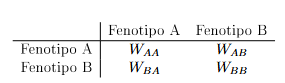

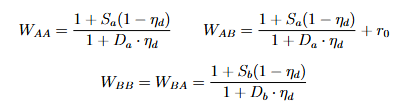

In [60]:
display(Image(filename='Payoff Matrix.png'))
display(Image(filename='WAA.png'))

Sean Sa y Sb el éxito reproductivo relativo asociado a cada fenotipo; 
Da  y Db, la facilidad con que cada uno es detectado y devorado por el depredador; 
nd es un número con valor entre 0  a 1 que habla de la densidad de depredadores  ;
r0 será un parámetro lineal adicional que representa una ventaja sexual adicional del fenotipo A cuando su contexto es solo de B's.

---
### Análisis de la  matriz

Analizaremos la diferencias de fitness en diferentes casos. 

In [61]:
def WAA(eta_d,s_a=0.86,d_a=0.107):
    return (1 +s_a*(1-eta_d))/(1+d_a*eta_d)

def WAB(eta_d,r0):
    return WAA(eta_d) + r0

def WBA(eta_d,s_b=0.53,d_b=0.023):
    return  (1 +s_b*(1-eta_d))/(1+d_b*eta_d)

def WBB(eta_d):
    return WBA(eta_d)

def pEstable(eta_d,r0): #Punto de estabilidad
    return (WBB(eta_d) - WAB(eta_d,r0) ) / (WAA(eta_d) - WAB(eta_d,r0 )  -WBA(eta_d) + WBB(eta_d))

In [62]:
# Diferencia entre los payoffs
def D(eta_d):
    return WAA(eta_d) - WBA(eta_d)


# Diferencia de fitness del modelo lineal
def delta_lineal(p, eta_d, r0):
    piA = p*WAA(eta_d) + (1-p)*WAB(eta_d, r0)
    piB = p*WBA(eta_d) + (1-p)*WBB(eta_d)
    return piA - piB


# Clasificación de estabilidad
def clasificar(eta_d, r0, tol=1e-8):

    a = D(eta_d)
    b = a + r0

    if abs(a) <= tol and abs(b) <= tol:
        return "Neutralidad"

    if a > tol and b > tol:
        return "A domina"

    if a < -tol and b < -tol:
        return "B domina"

    if a < -tol and b > tol:
        return "Coexistencia estable"

    if a > tol and b < -tol:
        return "Biestabilidad"

    return "Frontera/Indefinido"


# Equilibrio interior (si existe)
def p_interior(eta_d, r0):

    if abs(r0) < 1e-13:
        return None

    p = 1 + D(eta_d)/r0

    return p if 0 < p < 1 else None


# 1. Resolver eta_d crítico
eta_critico = brentq(D, 0, 1, xtol=1e-14)

# 2. Seleccionar eta a ambos lados de la frontera
eta_A = 2/3
eta_B = 8/9

# 3. Encontrar frontera de r0 en eta_B
r_frontera_B = brentq(
    lambda r: delta_lineal(0, eta_B, r),
    0, 0.25
)

# 4. Dominancia A: punto dentro de su región
r_A = 0.10

# 5. Dominancia B: punto por debajo de la frontera
r_B = r_frontera_B/2

# 6. Coexistencia: resolver r0 con p*=0.5
r_coex = brentq(
    lambda r: delta_lineal(0.5, eta_B, r),
    0, 0.25,
    xtol=1e-14
)

# 7. Biestabilidad: resolver r0 con p*=0.5
# Requiere permitir r0 negativo
r_biest = brentq(
    lambda r: delta_lineal(0.5, eta_A, r),
    -0.25, 0,
    xtol=1e-14
)

# 8. Neutralidad
r_neutral = 0.0

# Resultados
puntos = [
    (eta_A, r_A),
    (eta_B, r_B),
    (eta_B, r_coex),
    (eta_A, r_biest),
    (eta_critico, r_neutral)
]

print(f"Eta crítico: {eta_critico:.12f}")
print(f"Frontera r0 en eta_B: {r_frontera_B:.12f}")
print()

for eta, r0 in puntos:

    regimen = clasificar(eta, r0)
    p_eq = p_interior(eta, r0)

    print(f"Régimen: {regimen}")
    print(f"  eta_d = {eta:.12f}")
    print(f"  r0    = {r0:.12f}")
    print(f"  p interior = {p_eq}")
    print()


Eta crítico: 0.781888907954
Frontera r0 en eta_B: 0.037268371872

Régimen: A domina
  eta_d = 0.666666666667
  r0    = 0.100000000000
  p interior = None

Régimen: B domina
  eta_d = 0.888888888889
  r0    = 0.018634185936
  p interior = None

Régimen: Coexistencia estable
  eta_d = 0.888888888889
  r0    = 0.074536743744
  p interior = 0.5

Régimen: Biestabilidad
  eta_d = 0.666666666667
  r0    = -0.084197460143
  p interior = 0.5

Régimen: Neutralidad
  eta_d = 0.781888907954
  r0    = 0.000000000000
  p interior = None



In [63]:
def p_dot(p, eta_d, r0):
    piA = p * WAA(eta_d) + (1-p) * WAB(eta_d, r0)
    piB = p * WBA(eta_d) + (1-p) * WBB(eta_d)

    return p * (1-p) * (piA-piB)


def p_equilibrium(eta_d, r0):

    a = WAA(eta_d) - WBA(eta_d)
    b = WAB(eta_d, r0) - WBB(eta_d)

    if a > 0 and b > 0:
        return 1.0

    if a < 0 and b < 0:
        return 0.0

    # Coexistencia estable
    if a < 0 and b > 0:
        return (pEstable(eta_d,r0))

    return None

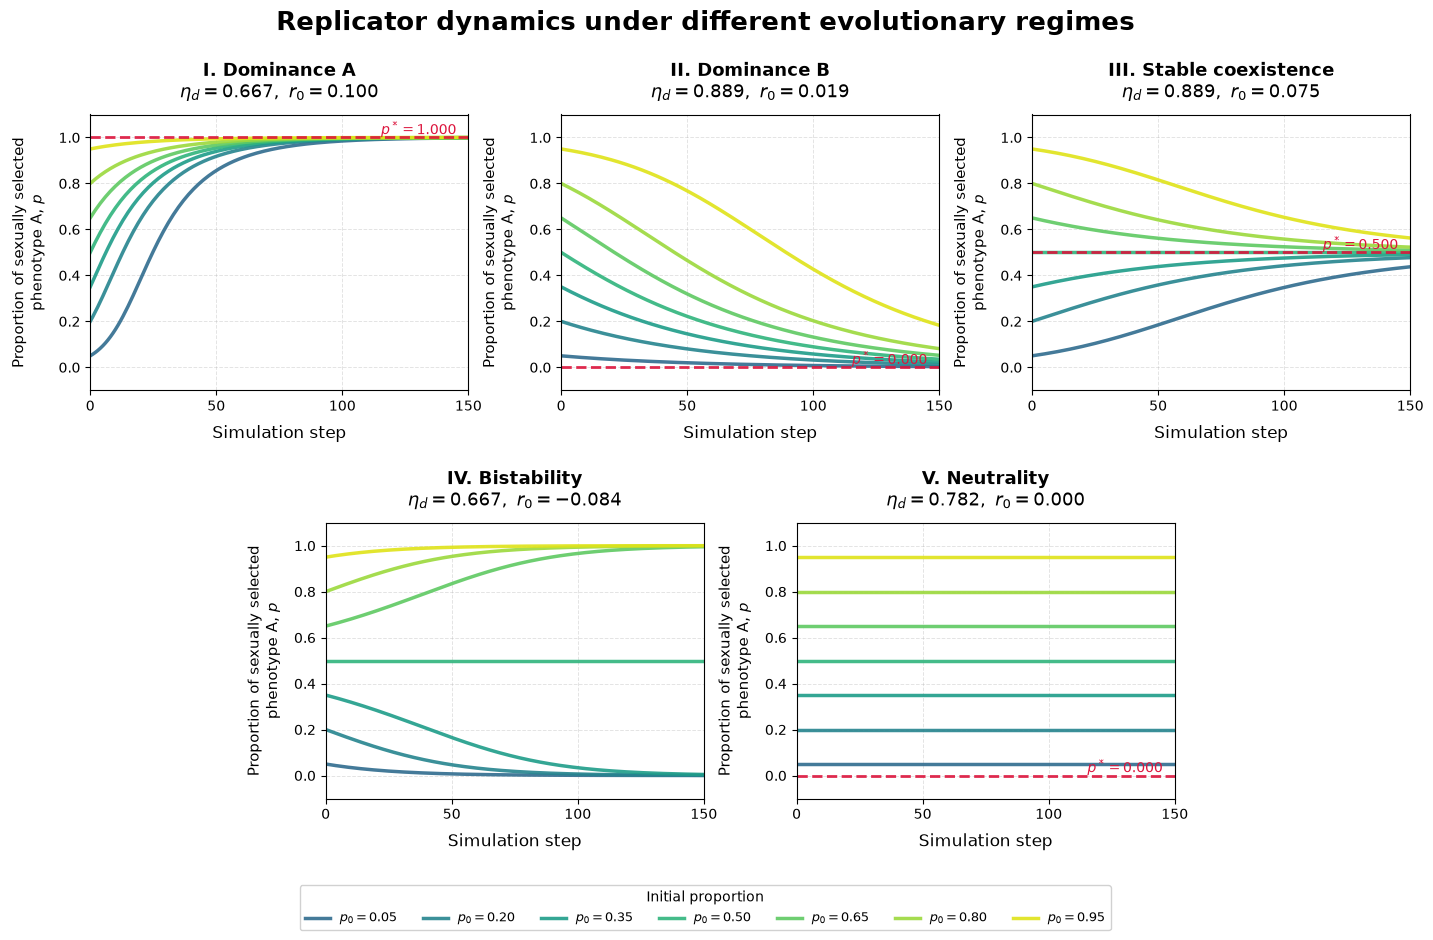

In [64]:

initial_p = [0.05, 0.20, 0.35, 0.50, 0.65, 0.80, 0.95]

colors = plt.cm.viridis([
    0.35, 0.45, 0.55, 0.65,
    0.75, 0.85, 0.95
])



cases = [
    ('I. Dominance A', 2/3, 0.100000000000),
    ('II. Dominance B', 8/9, 0.018634185936),
    ('III. Stable coexistence', 8/9, 0.074536743744),
    ('IV. Bistability', 2/3, -0.084197460143),
    ('V. Neutrality', 0.781888907954, 0.0),
]


def plot_five_regimes(n_steps=150, save_name='Replicator'):

    steps = np.arange(n_steps + 1)

    fig = plt.figure(figsize=(15, 9.5))

    gs = fig.add_gridspec(
        2, 6,
        hspace=0.48,
        wspace=0.65
    )

    axs = [
        fig.add_subplot(gs[0, 0:2]),
        fig.add_subplot(gs[0, 2:4]),
        fig.add_subplot(gs[0, 4:6]),
        fig.add_subplot(gs[1, 1:3]),
        fig.add_subplot(gs[1, 3:5])
    ]

    for ax, (title, eta_d, r0) in zip(axs, cases):

        # Calcular equilibrio estable
        p_star = p_equilibrium(eta_d, r0)

        for p0, color in zip(initial_p, colors):

            sol = solve_ivp(
                lambda t, y: [p_dot(y[0], eta_d, r0)],
                (0, n_steps),
                [p0],
                t_eval=steps,
                rtol=1e-9,
                atol=1e-11
            )

            if not sol.success:
                raise RuntimeError(sol.message)

            ax.plot(
                steps,
                sol.y[0],
                color=color,
                linewidth=2.5,
                alpha=0.9,
                label=fr'$p_0={p0:.2f}$'
            )

        # Línea horizontal del equilibrio
        if p_star is not None:

            ax.axhline(
                y=p_star,
                color='crimson',
                linestyle='--',
                linewidth=2,
                alpha=0.9,
                label=fr'Equilibrium $p^*={p_star:.3f}$'
            )

            ax.text(
                0.97,
                p_star,
                fr'$p^*={p_star:.3f}$',
                transform=ax.get_yaxis_transform(),
                fontsize=10,
                color='crimson',
                ha='right',
                va='bottom'
            )

        ax.set_title(
            title + '\n' +
            fr'$\eta_d={eta_d:.3f},\ r_0={r0:.3f}$',
            fontsize=13,
            fontweight='bold',
            pad=12
        )

        ax.set_xlabel(
            'Simulation step',
            fontsize=12,
            labelpad=8
        )

        ax.set_ylabel(
            'Proportion of sexually selected\n'
            r'phenotype A, $p$',
            fontsize=11,
            labelpad=8
        )

        ax.set_xlim(0, n_steps)
        ax.set_ylim(-0.1, 1.1)

        ax.set_xticks(
            np.arange(0, n_steps + 1, 50)
        )

        ax.grid(
            True,
            linestyle='--',
            linewidth=0.7,
            alpha=0.35
        )

        ax.tick_params(
            axis='both',
            labelsize=10
        )

    # Leyenda de condiciones iniciales
    handles, labels = axs[0].get_legend_handles_labels()

    fig.legend(
        handles[:len(initial_p)],
        labels[:len(initial_p)],
        title='Initial proportion',
        fontsize=9,
        title_fontsize=10,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.015),
        ncol=7,
        frameon=True,
        fancybox=True,
        framealpha=0.9
    )

    fig.suptitle(
        'Replicator dynamics under different evolutionary regimes',
        fontsize=19,
        fontweight='bold',
        y=0.99
    )

    fig.subplots_adjust(
        top=0.88,
        bottom=0.16,
        left=0.09,
        right=0.97
    )

    fig.savefig(
        f'../Gráficas/{save_name}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


plot_five_regimes()

In [65]:
def pmax(eta_d, r0):
    FA = WAA(eta_d)
    FB = WBB(eta_d)

    # Caso r0 = 0
    if abs(r0) < 1e-12:
        if abs(FA - FB) < 1e-10:
            return None  # Cualquier p maximiza el fitness
        return 1.0 if FA > FB else 0.0

    # Punto estacionario
    p_est = (FA - FB + r0) / (2*r0)

    # Posibles máximos dentro de [0, 1]
    candidatos = [0.0, 1.0]

    if 0 < p_est < 1:
        candidatos.append(p_est)

    # Fitness promedio
    def fitness(p):
        return FB + p*(FA-FB+r0) - r0*p**2

    return max(candidatos, key=fitness)


eta_d = [eta_A, eta_B, eta_B, eta_A, eta_critico]
r0 = [r_A, r_B, r_coex, r_biest, r_neutral]

pmaxs = []

for i in range(5):
    x = pmax(eta_d[i], r0[i])
    pmaxs.append(x)

print(pmaxs)


[0.7104936503584742, 0.0, 0.25, 1.0, None]


2. Miramos para fitness dependientes de la frecuencia del fenotipo. 

Con el fin de estudiar la dinámica de los alelos según el grupo en el que se encuentran, consideraremos dos situaciones extremas: cuando el individuo focal está rodeado por individuos con su mismo alelo y cuando está rodeado por individuos con el alelo alternativo. Estos casos límite permiten evidenciar que el fitness no es una propiedad fija del alelo, sino que depende de su frecuencia en la población o grupo local

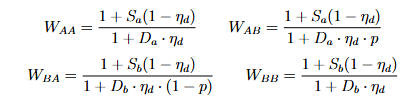

In [66]:
display(Image(filename='WBB.png'))

Dónde p será la densidad de individuos tipo A que hay en la población.

In [67]:
def WAA(eta_d,s_a=0.68,d_a=0.107):
    return (1 +s_a*(1-eta_d))/(1+d_a*eta_d)

def WAB(eta_d,p,s_a=0.68,d_a=0.107):
    return (1 +s_a*(1-eta_d))/(1+d_a*eta_d*p)

def WBA(eta_d,p,s_b=0.54,d_b=0.040):
    return (1 +s_b*(1-eta_d))/(1+d_b*eta_d*(1-p))

def WBB(eta_d,s_b=0.54,d_b=0.040):
    return (1 +s_b*(1-eta_d))/(1+d_b*eta_d)


# Fitness de cada fenotipo
def fitness(p, eta_d):
    piA = p*WAA(eta_d) + (1-p)*WAB(eta_d, p)
    piB = p*WBA(eta_d, p) + (1-p)*WBB(eta_d)
    return piA, piB

# Diferencia de fitness
def delta(p, eta_d):
    piA, piB = fitness(p, eta_d)
    return piA - piB

# Ecuación del replicador
def p_dot(p, eta_d):
    return p*(1-p)*delta(p, eta_d)


In [68]:
def pEstableFrecuencia(eta_d, tol=1e-10):

    d0 = delta(0, eta_d)
    d1 = delta(1, eta_d)

    # Dominancia de A
    if d0 > tol and d1 >= -tol:
        return 1.0

    # Dominancia de B
    if d0 <= tol and d1 < -tol:
        return 0.0

    # Coexistencia estable
    if d0 > tol and d1 < -tol:
        return brentq(
            lambda p: delta(p, eta_d),
            0, 1,
            xtol=1e-14
        )

    # Posibles casos no contemplados
    return None

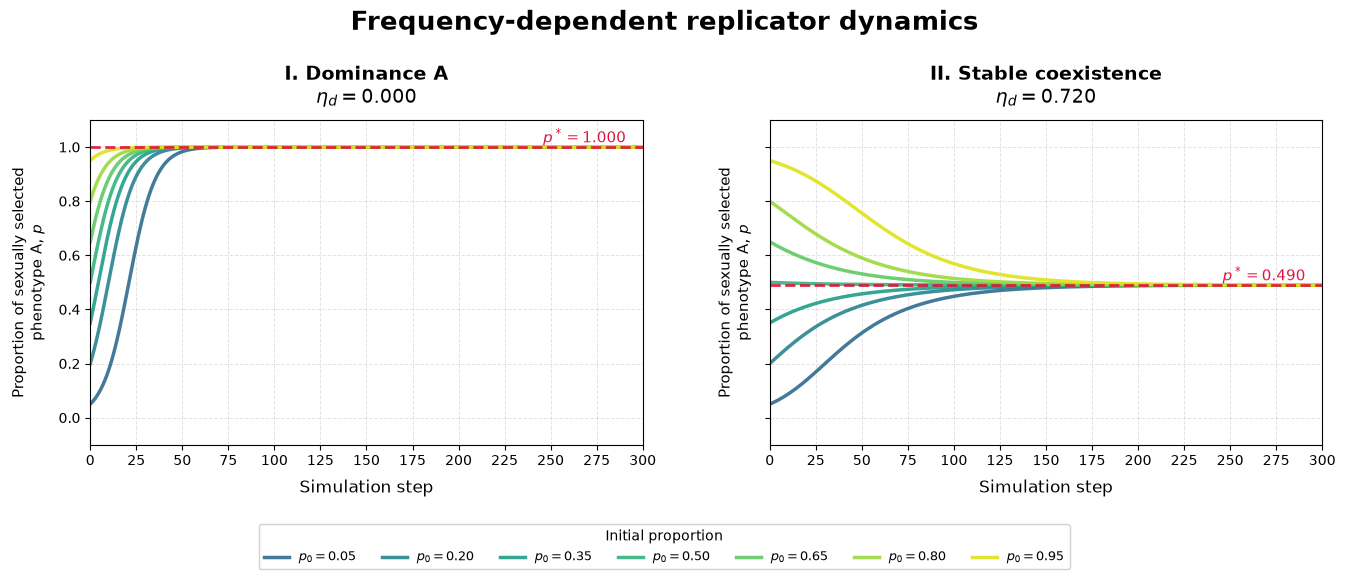

In [69]:

initial_p = [0.05, 0.20, 0.35, 0.50, 0.65, 0.80, 0.95]

colors = plt.cm.viridis([
    0.35, 0.45, 0.55, 0.65, 0.75, 0.85, 0.95
])

cases = [
    ('I. Dominance A', 0),
    ('II. Stable coexistence', 0.72),
]


def plot_two_regimes(n_steps=300,
                     save_name='Frequency_Dependent_Replicator'):

    steps = np.arange(n_steps + 1)

    fig, axs = plt.subplots(
        1, 2,
        figsize=(14, 5.8),
        sharex=True,
        sharey=True
    )

    for ax, (title, eta_d) in zip(axs, cases):

        # Calcular equilibrio estable
        p_star = pEstableFrecuencia(eta_d)

        for p0, color in zip(initial_p, colors):

            sol = solve_ivp(
                lambda t, y: [p_dot(y[0], eta_d)],
                (0, n_steps),
                [p0],
                t_eval=steps,
                rtol=1e-9,
                atol=1e-11
            )

            if not sol.success:
                raise RuntimeError(sol.message)

            ax.plot(
                steps,
                sol.y[0],
                color=color,
                linewidth=2.5,
                alpha=0.9,
                label=fr'$p_0={p0:.2f}$'
            )

        # Línea horizontal del equilibrio estable
        if p_star is not None:

            ax.axhline(
                y=p_star,
                color='crimson',
                linestyle='--',
                linewidth=2,
                alpha=0.9
            )

            ax.text(
                0.97,
                p_star,
                fr'$p^*={p_star:.3f}$',
                transform=ax.get_yaxis_transform(),
                fontsize=11,
                color='crimson',
                ha='right',
                va='bottom'
            )

        ax.set_title(
            title + '\n' + fr'$\eta_d={eta_d:.3f}$',
            fontsize=14,
            fontweight='bold',
            pad=12
        )

        ax.set_xlabel(
            'Simulation step',
            fontsize=12,
            labelpad=8
        )

        ax.set_ylabel(
            'Proportion of sexually selected\n'
            r'phenotype A, $p$',
            fontsize=11,
            labelpad=8
        )

        ax.set_xlim(0, n_steps)
        ax.set_ylim(-0.1, 1.1)

        ax.set_xticks(
            np.arange(0, n_steps + 1, 25)
        )

        ax.grid(
            True,
            linestyle='--',
            linewidth=0.7,
            alpha=0.35
        )

        ax.tick_params(axis='both', labelsize=10)

    handles, labels = axs[0].get_legend_handles_labels()

    fig.legend(
        handles,
        labels,
        title='Initial proportion',
        fontsize=9,
        title_fontsize=10,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.015),
        ncol=7,
        frameon=True,
        fancybox=True,
        framealpha=0.9
    )

    fig.suptitle(
        'Frequency-dependent replicator dynamics',
        fontsize=19,
        fontweight='bold',
        y=0.99
    )

    fig.subplots_adjust(
        top=0.80,
        bottom=0.24,
        left=0.09,
        right=0.97,
        wspace=0.23
    )

    fig.savefig(
        f'../Gráficas/{save_name}.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()


plot_two_regimes()


3. Matriz de Transicion.

In [70]:

def matriz_transicion(N, eta_d):

    T = np.zeros((N + 1, N + 1))

    for i in range(N + 1):

        # Proporción actual del fenotipo A
        p = i / N

        # Fitness esperados definidos anteriormente
        piA, piB = fitness(p, eta_d)

        # Fitness total ponderado
        denominador = i*piA + (N-i)*piB

        # Estados absorbentes
        if i == 0 or i == N:
            T[i, i] = 1.0
            continue

        # Probabilidad de aumentar individuos A
        T_mas = (
            (i*piA / denominador)
            * ((N-i)/N)
        )

        # Probabilidad de disminuir individuos A
        T_menos = (
            ((N-i)*piB / denominador)
            * (i/N)
        )

        # Probabilidad de permanecer en el mismo estado
        T_igual = 1 - T_mas - T_menos

        # Construcción de la matriz
        T[i, i+1] = T_mas
        T[i, i-1] = T_menos
        T[i, i] = T_igual

    return T


In [71]:

def tiempo_convergencia(M, x0, tol=1e-8, max_steps=100000):

    x = np.asarray(x0, dtype=float).copy()

    for T in range(max_steps + 1):

        # Probabilidad que permanece en estados interiores
        prob_transitoria = np.sum(x[1:-1])

        if prob_transitoria < tol:
            return T, x

        x = x @ M

    return None, x


In [114]:
N, eta_d = 1000, 0.72 
M = matriz_transicion(N, eta_d)

print(M)


# Distribución inicial: toda la probabilidad en i=N//2
N = M.shape[0] - 1

x0 = np.zeros(N + 1)
x0[N // 2] = 1.0

T, x_final = tiempo_convergencia(M, x0)

print("Tiempo de convergencia:", T)
print("Distribución final:", x_final)
print("Probabilidad de fijación de B:", x_final[0])
print("Probabilidad de fijación de A:", x_final[-1])

[[1.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [9.98936394e-04 9.97938521e-01 1.06254278e-03 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 [0.00000000e+00 1.99574648e-03 9.95881745e-01 ... 0.00000000e+00
  0.00000000e+00 0.00000000e+00]
 ...
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 9.95925595e-01
  1.99583453e-03 0.00000000e+00]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 1.04042905e-03
  9.97960612e-01 9.98958529e-04]
 [0.00000000e+00 0.00000000e+00 0.00000000e+00 ... 0.00000000e+00
  0.00000000e+00 1.00000000e+00]]
Tiempo de convergencia: None
Distribución final: [3.36009627e-07 1.66283030e-08 1.73999015e-08 ... 1.39727557e-07
 1.34617685e-07 2.50120509e-06]
Probabilidad de fijación de B: 3.360096273968185e-07
Probabilidad de fijación de A: 2.5012050856856833e-06


In [115]:
def analizar_ecuacion_maestra(M, x0, n_pasos=20000):

    N = M.shape[0] - 1
    x = np.asarray(x0, dtype=float).copy()

    # Frecuencias posibles de A
    frecuencias = np.arange(N + 1) / N

    # Distribuciones a lo largo de la evolución
    distribuciones = [x.copy()]

    for n in range(n_pasos):
        x = x @ M
        distribuciones.append(x.copy())

    distribuciones = np.array(distribuciones)

    # Probabilidad de fijación acumulada en cada paso
    prob_A = distribuciones[:, -1]
    prob_B = distribuciones[:, 0]

    # Probabilidad de continuar en estados transitorios
    supervivencia = distribuciones[:, 1:-1].sum(axis=1)

    # Proporción promedio de A
    media = distribuciones @ frecuencias

    # Varianza de la proporción de A
    varianza = (
        distribuciones @ (frecuencias**2) - media**2
    )

    # Submatriz de estados transitorios
    Q = M[1:-1, 1:-1]
    I = np.eye(N - 1)

    # Tiempo medio exacto de absorción por estado
    tiempos = np.linalg.solve(
        I - Q,
        np.ones(N - 1)
    )

    tiempo_medio = x0[1:-1] @ tiempos

    # Probabilidad eventual de fijación de A
    fijacion_A = np.zeros(N + 1)
    fijacion_A[-1] = 1.0

    fijacion_A[1:-1] = np.linalg.solve(
        I - Q,
        M[1:-1, -1]
    )

    prob_fijacion_A = x0 @ fijacion_A
    prob_fijacion_B = 1 - prob_fijacion_A

    return {
        "distribuciones": distribuciones,
        "prob_A": prob_A,
        "prob_B": prob_B,
        "supervivencia": supervivencia,
        "media": media,
        "varianza": varianza,
        "tiempo_medio": tiempo_medio,
        "fijacion_A": prob_fijacion_A,
        "fijacion_B": prob_fijacion_B
    }


In [ ]:

# Distribución inicial concentrada en el estado central
x0 = np.zeros(M.shape[0])
x0[(M.shape[0] - 1)//2] = 1.0


resultados = analizar_ecuacion_maestra(
    M, x0, n_pasos=150000
)

print("Fijación eventual de A:",
      resultados["fijacion_A"])

print("Fijación eventual de B:",
      resultados["fijacion_B"])

print("Tiempo medio de absorción:",
      resultados["tiempo_medio"])


KeyboardInterrupt: 

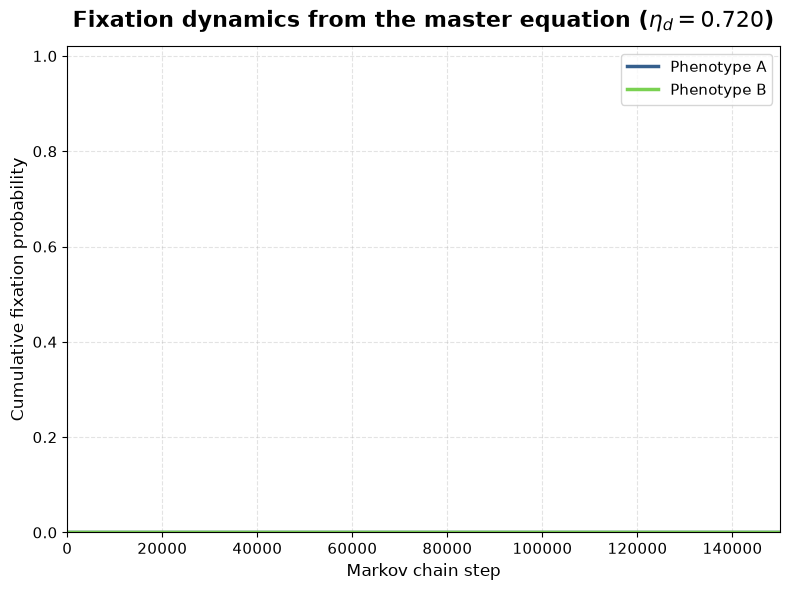

In [ ]:

# Distribuciones obtenidas de la ecuación maestra
P = resultados["distribuciones"]

# Número de estados y pasos de la cadena
N = P.shape[1] - 1
steps = np.arange(P.shape[0])

# Probabilidades acumuladas de fijación
P_fix_A = P[:, N]
P_fix_B = P[:, 0]

# Colores Viridis
colors = plt.cm.viridis([0.30, 0.80])

# Una sola gráfica
fig, ax = plt.subplots(figsize=(8, 6))

# Fijación del fenotipo A
ax.plot(
    steps,
    P_fix_A,
    color=colors[0],
    linewidth=2.5,
    label="Phenotype A"
)

# Fijación del fenotipo B
ax.plot(
    steps,
    P_fix_B,
    color=colors[1],
    linewidth=2.5,
    label="Phenotype B"
)

ax.set_title(
    fr"Fixation dynamics from the master equation ($\eta_d={eta_d:.3f}$)",
    fontsize=16,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    "Markov chain step",
    fontsize=12
)

ax.set_ylabel(
    "Cumulative fixation probability",
    fontsize=12
)

ax.set_ylim(0, 1.02)
ax.set_xlim(0, steps[-1])

ax.grid(
    True,
    linestyle="--",
    alpha=0.35
)

ax.legend(
    fontsize=11,
    frameon=True
)

ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()
plt.show()


In [76]:
def DeltaW(x,y,func,n):
    X,Y = np.meshgrid(x,y)
    Z= np.zeros_like(X,dtype=float )
    for i in range(X.shape[0]):        
        for j in range(X.shape[1]):
            Z[i, j] = func(X[i, j], Y[i, j])[n]
    return X,Y,Z


In [ ]:
# Diferencia de fitness
def delta(p, eta_d):
    piA, piB = fitness(p, eta_d)
    return piA - piB


# Valores de los parámetros
eta_d = np.linspace(0, 1, 1000)
p = np.linspace(0, 1, 1000)

# Crear la malla
X, Y = np.meshgrid(eta_d, p)

# Calcular la diferencia de fitness
Z = delta(Y, X)

# Graficar
plotFL(
    tamanio=(850, 700),
    legendname="ΔΠ",
    tittle="Fitness difference: ΔΠ = ΠA - ΠB",
    xlabel="Predation intensity (η_d)",
    ylabel="Proportion of phenotype A (p)",
    save_name="FL_Teorico_1",
    X=X,
    Y=Y,
    Z=Z
)


In [ ]:
X,Y,Z = DeltaW(np.linspace(0, 1, 10000),np.linspace(0, 1, 10000), deltaWFilas, 1)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_BB - W_BA",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_2",
    X=X,
    Y=Y,
    Z=Z
)   

KeyboardInterrupt: 

In [ ]:

X,Y,Z = DeltaW(np.linspace(0, 1, 1000),np.linspace(0, 1, 1000), deltaWColumnas, 0)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_AA - W_BA",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_3",
    X=X,
    Y=Y,
    Z=Z
)   

In [ ]:
X,Y,Z = DeltaW(np.linspace(0, 1, 1000),np.linspace(0, 1, 1000), deltaWColumnas, 1)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_BB - W_BA",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_4",
    X=X,
    Y=Y,
    Z=Z
)   

In [ ]:
X,Y,Z = DeltaW(np.linspace(0, 1, 100),np.linspace(0, 1, 100), deltaWCruzado, 0)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_AA - W_BB",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_5",
    X=X,
    Y=Y,
    Z=Z
)   

In [ ]:
X,Y,Z = DeltaW(np.linspace(0, 1, 100),np.linspace(0, 1, 100), deltaWColumnas, 1)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_Ab - W_BA",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_6",
    X=X,
    Y=Y,
    Z=Z
)   

Para las gráficas utilizamos el mismo rango de color tal que podamos ver claramente en que rango se mueven teniendo encuenta el rango entre -0.2 y 0.2 que se mueven todas. Además se hicieron pruebas en el anexo para ver cuántos parámetros deberíamos de introducir en la grilla con el fin de ver lo más suave y continuo posible las diferencias de fitness. Se decidió tomar una grilla cuadrada de forma arbitraria, luego se decidió hacerla con un tamaño de  1000 x 1000 ya que aumentarle un orden de magnitud me cambiaba el tiempo de ploteo de 8.9s a  ,es decir, T10000 / T 1000= . 

Ahora para el fitness entre fias, es decir, siendo yo A ó B cómo me va en los  diferentes cardúmenes. 

En ambos casos vimos escalones muy pronunciados, hay alcantilados fuertes que me meustran que una pequeña varianza hace una disminución abruta de delta W haciendo que la tendencia puede oscilar muy rápidamente entre estados de dirección a una neutral a una negativa, y una forma tipo coliseo o tendencia cóncava dónde vemos que no hay una relación lineal entre las diferentes densidades la del fenotipo y la de depredación. Para A se estrecha cuando la densidad de A disminuye y aumenta la densidad de depredadodres que quiere decir que le va mejor al fenotipo A en el cardumen B. Cuando observamos el comportamiento de B se puede observar claramente menos escalones que antes por lo que varia muy poco el Delta W, veremos valores máximos cuándo p = 0 ,es decir, que la densidad de los de fenotipo B es máximo pb= 1- p y densidad depredación es mínima. 




---


### Proceso de Moran dado un fitness Dinámico

#### DEF de Poblaciones
Definimos **N** como la población, **p** como la proporción inicial de individuos de tipo A, siendo los de A los que tienen una elección sexualmás fuerte y B los menos favorecidos por esta selección.

In [84]:
def populationDef(N,p):
    """
    Crea una población de tamaño N con una proporción inicial p de individuos de tipo A y (1-p) de tipo B.
    """
    if p == 0 : 
        population = ['B'] * (N-1) + ['A']
    elif p == 1 :
        population = ['A'] * (N-1) + ['B']
    else:
        population = ['A'] * int(p * N) + ['B'] * int((1 - p) * N)
    return population

#### DEF de Mutaciones 
Definimos **N** como la población, **p** como la proporción inicial de individuos de tipo A, siendo los de A los que tienen una elección sexualmás fuerte y B los menos favorecidos por esta selección.

In [81]:
# Números de mutaciones [9,10]
nbases= 21*3642 ; nmutaciones = (5.97)*10**(-9); mu = nbases/(nmutaciones)
print(f"El número de generaciones necesarios para mutaciones es de {round(1/(nbases*nmutaciones)/10e2)} generaciones")

El número de generaciones necesarios para mutaciones es de 2 generaciones


In [82]:
def mutacionPeriodica(generacion, intervalo, population):
    """
    Aplica una mutación reversible cada `intervalo` generaciones.
    """
    if generacion % intervalo == 0:
        idx = np.random.randint(len(population))
        population[idx] = "B" if population[idx] == "A" else "A"
    return population

In [83]:
def mutacionPoisson(population):
    """
    Aplica mutaciones a la población.
    """

    lam = len(population) * 1/mu                      
    k = stats.poisson.rvs(lam)         # número real de mutaciones
    if k == 0:
            return population
        
    k = min(k, len(population))                   
    idxs = np.random.choice(len(population), size=k, replace=False)[0]

    if population[idxs] == "A":
        population[idxs] = "B"

    else:
        population[idxs] = "A"
    
    return population

---

## Dinámica poblacional de alelo elegido sexualmente dado parámetros de Guppies

Acá vamos a simular un proceso de Moran utilizando pesos estadísticos dados por el fitness de A o fitness de B y va a morir de forma aleatoria cualquier individuo. 

### Parámetros Biológicos

Voy a definir algunos parámetros importantes para el modelo computacional teórico basados en literatura y deducciones propias acordes únicamente en la población de los Guppies.


In [89]:
#Reproducción y Muerte
s_a = 0.86; s_b = 0.53; d_a = 0.107; d_b = 0.023 # Valores NO arbitrarios sacados de [4] y [7]
fit_A = (1+s_a); fit_B= (1+s_b); fitB_fitA = round(fit_B/fit_A,2)
print(f"Cuando ignoramos efectos no lineales, excluyendo depredación, vemos que la diferencia de fitness será: {fitB_fitA}" )

dead_A = 1/(1+d_a); dead_B= 1/(1+d_b) ; deadB_deadA = round((dead_B)/(dead_A),2)
print(f"Cuando ignoramos efectos no lineales, excluyendo apareamiento, vemos que la diferencia de fitness  será: {deadB_deadA}" )


Cuando ignoramos efectos no lineales, excluyendo depredación, vemos que la diferencia de fitness será: 0.82
Cuando ignoramos efectos no lineales, excluyendo apareamiento, vemos que la diferencia de fitness  será: 1.08


In [90]:
def MPFitDinamico(N, p,eta_d,T,g,poisson):
    """
    Simula un proceso de Moran para una población de tamaño N, con una proporción inicial p de individuos de tipo A y T generaciones.
    Devuelve la proporción final de individuos de tipo A después de T generaciones.
    """
    population = populationDef(N, p)
    history = []
    p0 = p 
    fit_a = (1+s_a*(1-eta_d))/(1+d_a*eta_d*p)
    fit_b= (1+s_b*(1-eta_d))/(1+d_b*eta_d*(1-p)) 

    for t in range(T):
        reproducer = random.choices(
                    population,
                    weights=[fit_a if x == 'A' else fit_b for x in population]
                )[0]
        to_die = random.choices(population)[0]
        population[population.index(to_die)] = reproducer 
        if g > 1  : #Asumimos que hay mutación
            population = mutacionPeriodica(t,g,population)
        elif poisson: 
            population = mutacionPoisson(population)
        p0 = population.count('A') / len(population)
        history.append(p0)
    return round(population.count('A') / len(population), 1), history, fit_a,fit_b

1. Dinámica en estados límite sin depredación y con densidad de depredación máxima. Con mutación tipo Poisson

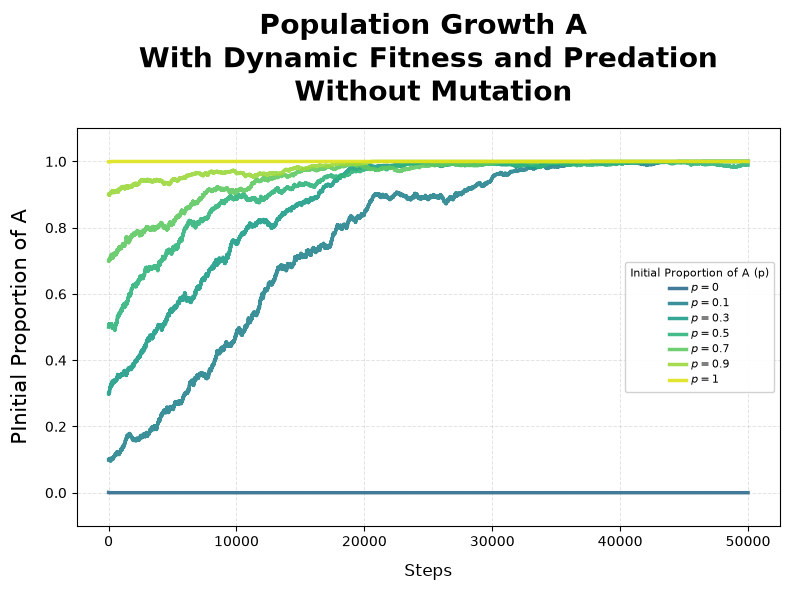

In [95]:
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Initial Proportion of A (p)", tittle="Population Growth A \n With Dynamic Fitness and Predation \n Without Mutation", 
     xlabel="Steps", ylabel="PInitial Proportion of A", save_name="PM_FitFijo_DepreFija",
       process_func=MPFitDinamico, N=1000,  eta_d= 0, T=50000, g=0 ,poisson= False)

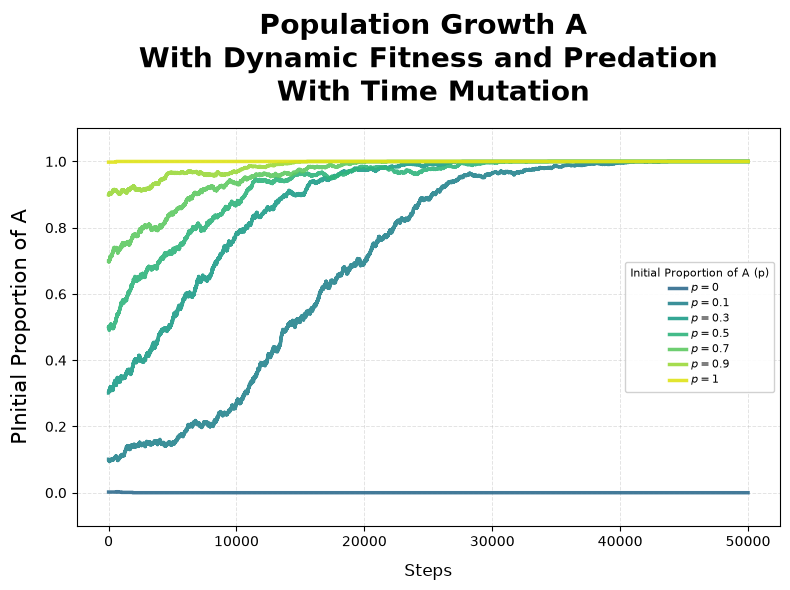

In [99]:
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Initial Proportion of A (p)", tittle="Population Growth A \n With Dynamic Fitness and Predation \n With Time Mutation", 
     xlabel="Steps", ylabel="PInitial Proportion of A", save_name="PM_FitFijo_DepreFija",
       process_func=MPFitDinamico, N=1000,  eta_d= 0, T=50000, g=mu ,poisson= False)

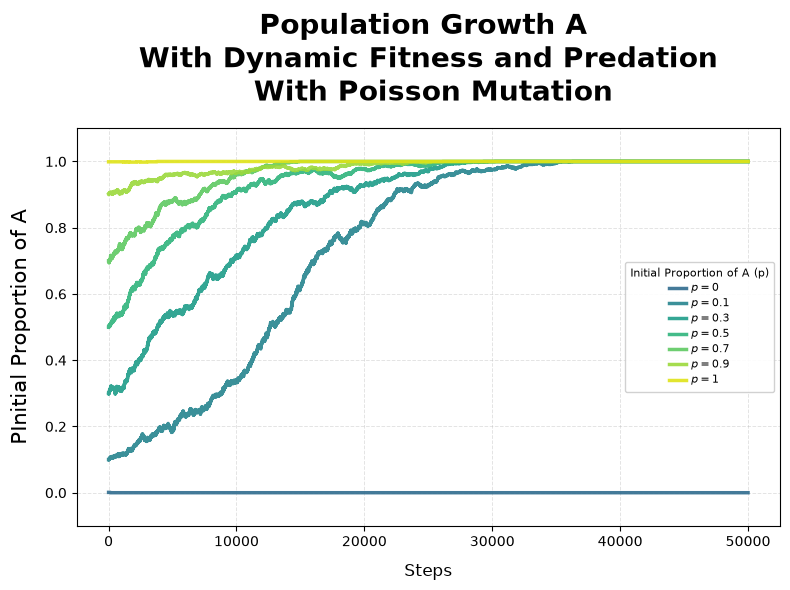

In [98]:
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Initial Proportion of A (p)", tittle="Population Growth A \n With Dynamic Fitness and Predation \n With Poisson Mutation", 
     xlabel="Steps", ylabel="PInitial Proportion of A", save_name="PM_FitFijo_DepreFija",
       process_func=MPFitDinamico, N=1000,  eta_d= 0, T=50000, g=0 ,poisson= True)

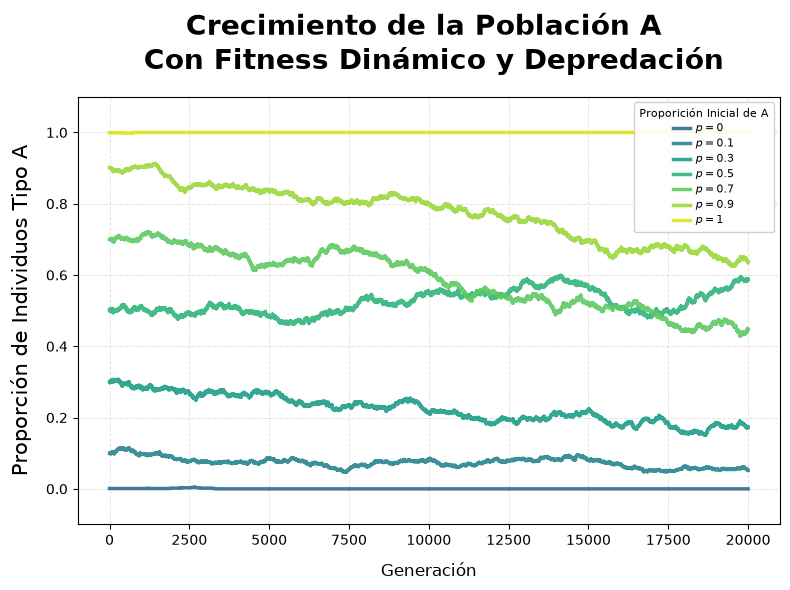

In [ ]:
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Con Fitness Dinámico y Depredación", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="PM_FitFijo_DepreFija",
       process_func=MPFitDinamico, N=1000,  eta_d= 1, T=20000, g=0 ,poisson= True)

2. Fitness Landscape para esta matriz propuesta

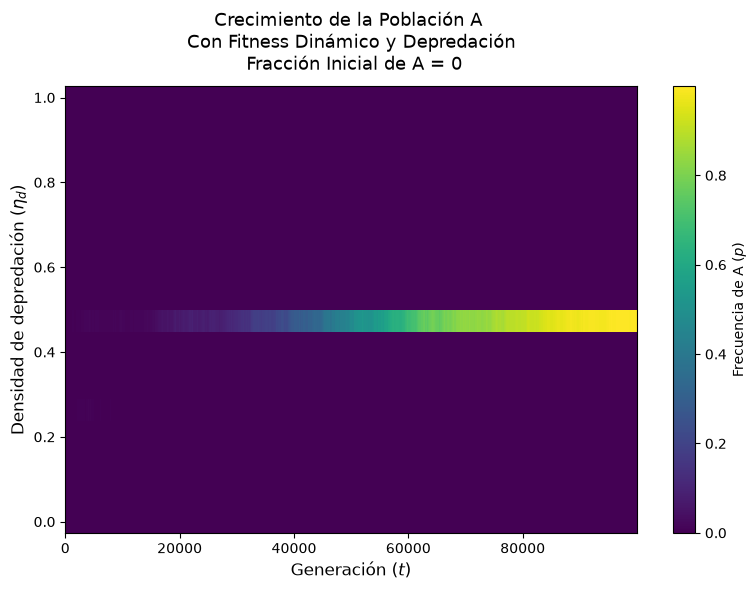

In [ ]:
plotHeat(
    tamanio=(8, 6),
    p=0,  # Valor fijo de p
    legendname="Frecuencia de A ($p$)", 
    tittle= f"Crecimiento de la Población A \n Con Fitness Dinámico y Depredación \n Fracción Inicial de A = {0}", 
    xlabel="Generación ($t$)", 
    ylabel="Densidad de depredación ($\\eta_d$)", 
    save_name="HeatMap_FitFijo",
    process_func=MPFitDinamico, 
    N=1000,  
    T=100000, 
    g=0, 
    poisson=True,
    num_eta=20  
)

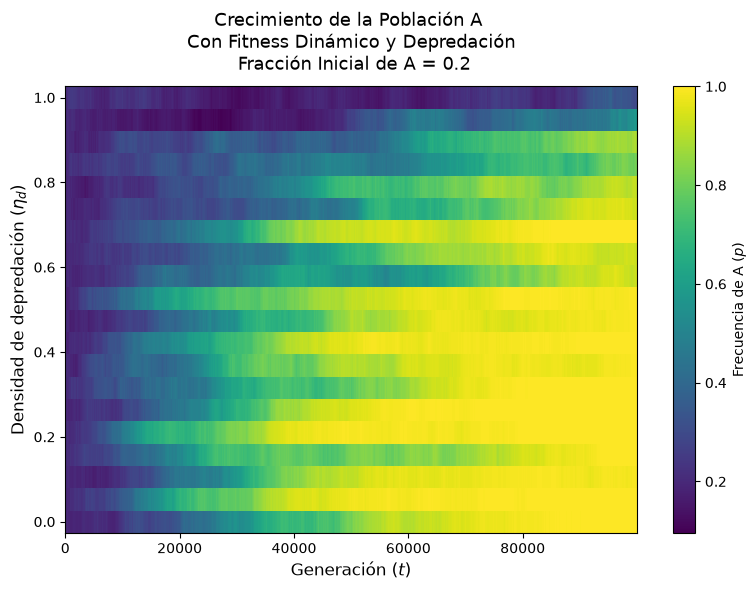

In [ ]:
plotHeat(
    tamanio=(8, 6),
    p=0.2,  # Valor fijo de p
    legendname="Frecuencia de A ($p$)", 
    tittle=f"Crecimiento de la Población A \n Con Fitness Dinámico y Depredación \n Fracción Inicial de A = {0.2}", 
    xlabel="Generación ($t$)", 
    ylabel="Densidad de depredación ($\\eta_d$)", 
    save_name="HeatMap_FitFijo",
    process_func=MPFitDinamico, 
    N=1000,  
    T=100000, 
    g=0, 
    poisson=True,
    num_eta=20  
)

In [ ]:
plotHeat(
    tamanio=(8, 6),
    p=0.5,  # Valor fijo de p
    legendname="Frecuencia de A ($p$)", 
    tittle=f"Crecimiento de la Población A \n Con Fitness Dinámico y Depredación \n Fracción Inicial de A = {0.5}", 
    xlabel="Generación ($t$)", 
    ylabel="Densidad de depredación ($\\eta_d$)", 
    save_name="HeatMap_FitFijo",
    process_func=MPFitDinamico, 
    N=1000,  
    T=100000, 
    g=0, 
    poisson=True,
    num_eta=20  
)

KeyboardInterrupt: 

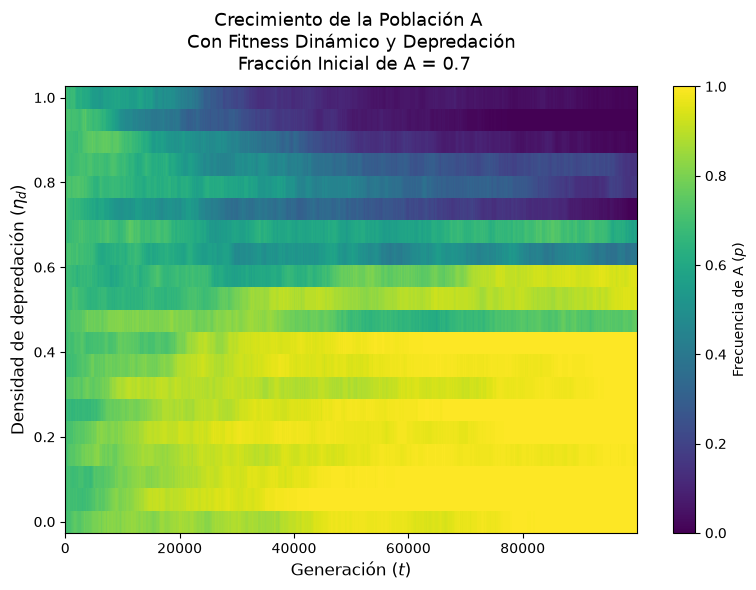

In [ ]:
plotHeat(
    tamanio=(8, 6),
    p=0.7,  # Valor fijo de p
    legendname="Frecuencia de A ($p$)", 
    tittle=f"Crecimiento de la Población A \n Con Fitness Dinámico y Depredación \n Fracción Inicial de A = {0.7}", 
    xlabel="Generación ($t$)", 
    ylabel="Densidad de depredación ($\\eta_d$)", 
    save_name="HeatMap_FitFijo",
    process_func=MPFitDinamico, 
    N=1000,  
    T=100000, 
    g=0, 
    poisson=True,
    num_eta=20  
)

Sin Importar que hagamos respecto a la densidad de depredadores vemos que hay una clara fijación del alelo sexual elegido sin importar el valor que eligamos. Por lo tanto, agregaremos un costo adicional para los peces con mayor frecuencia. Que veremos, que dinámica me da a medida que muevo c. 

In [ ]:
def WA(p, s_a, d_a, eta_d, c=0.0):
    base_A = (1 + s_a) / (1 + d_a * eta_d)
    competencia = 1 / (1 + d_a*p * c * eta_d) 
    return base_A * competencia 

def WB(p, s_b, d_b, eta_d, c=0.0):
    base_B = (1 + s_b) / (1 + d_b * eta_d)
    competencia =  (1.0 + d_b*(1-p) * c * eta_d)   
    return base_B * competencia 

def delta_W(p, c, eta_d=1.0):
    fita = WA(p, s_a,d_a,eta_d,c)
    fitb= WB(p,s_b,d_b,eta_d,c)
    return (fita-fitb)

def clasificar(c, eta_d=1.0):
    delta_0 = delta_W(0, c, eta_d)
    delta_1 = delta_W(1, c, eta_d)
    if delta_0 > 0 and delta_1 < 0: return "Coexistencia"
    if delta_0 < 0 and delta_1 > 0: return "Biestabilidad"
    if delta_0 > 0 and delta_1 > 0: return "Dominancia A"
    if delta_0 < 0 and delta_1 < 0: return "Dominancia B"
    return "Caso límite"

for c in [0.0, 0.5, 1.0, 2.0, 5.0]:
    print(f"c = {c:5.2f}  ->  {clasificar(c)}")


c =  0.00  ->  Dominancia A
c =  0.50  ->  Coexistencia
c =  1.00  ->  Dominancia B
c =  2.00  ->  Dominancia B
c =  5.00  ->  Dominancia B


---

## Definición de Matriz de Pagos Dinámica
---

Con parámetros no lineales como oddity , etc 
Por explorar ... 


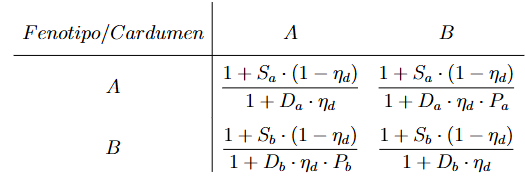

In [ ]:
display(Image(filename='Payoff Matrix.png'))

In [ ]:
def r(p, eta_d, eta_c, s_a, r0):
    """Ventaja sexual de A: proporcional a la frecuencia de B (1 - p)."""
    f = max(0.0, 1.0 - eta_d / eta_c)
    return s_a * r0 * (1 - p) * f

def o(o0, fenotipo, population, eta_d):
    n_A = population.count('A')
    x_prom = n_A / len(population)
    return o0 * eta_d * abs(fenotipo - x_prom)

def d(d0, eta_d, p, k0):
    return d0 * eta_d * (1 - np.exp(-k0 * p))

def WA(p, s_a, d_a, eta_d, eta_c, r0, o0):
    base_A = (1 + s_a) / (1 + d_a * eta_d)
    r_val = r(p, eta_d, eta_c, s_a, r0)
    o_A = o0 * eta_d * (1 - p)
    return base_A + r_val - o_A

def WB(p, s_b, d_b, eta_d, d0, k0, o0):
    base_B = (1 + s_b) / (1 + d_b * eta_d)
    d_val = d(d0, eta_d, p, k0)
    o_B = o0 * eta_d * p
    return base_B + d_val - o_B

def delta_W(p, r0, o0, d0, eta_d, eta_c, k0):
    f = max(0.0, 1.0 - eta_d / eta_c)
    r_val = s_a * r0 * (1 - p) * f
    o_A = o0 * eta_d * abs(1 - p)
    o_B = o0 * eta_d * abs(p)
    d_val = d0 * eta_d * (1 - np.exp(-k0 * p))
    base = (1 + s_a)/(1 + d_a*eta_d) - (1 + s_b)/(1 + d_b*eta_d)
    return base + r_val - o_A + o_B - d_val

In [ ]:
def clasificar(r0, o0, d0, k0, eta_d=1, eta_c=0.5):
    delta_0 = delta_W(0, r0, o0, d0, eta_d, eta_c, k0)
    delta_1 = delta_W(1, r0, o0, d0, eta_d, eta_c, k0)
    if delta_0 > 0 and delta_1 < 0: return "Coexistencia"
    if delta_0 < 0 and delta_1 > 0: return "Biestabilidad"
    if delta_0 > 0 and delta_1 > 0: return "Dominancia A"
    if delta_0 < 0 and delta_1 < 0: return "Dominancia B"
    return "Caso límite"

# Barrido
resultados = []
for r0 in np.arange(0, 0.25, 0.5):
    for o0 in np.arange(0.01, 1, 0.1):
        for d0 in np.arange(0.01, 1.5, 0.1):
            for k0 in [0.5, 1.0, 2.0, 5.0]:
                tipo = clasificar(r0, o0, d0, k0)
                resultados.append({
                    "r0": r0, "o0": round(o0, 2), "d0": round(d0, 2),
                    "k0": k0, "comportamiento": tipo
                })

df = pd.DataFrame(resultados)
print(df["comportamiento"].value_counts())
print(df.iloc[200:300])

comportamiento
Biestabilidad    301
Dominancia B     239
Coexistencia      55
Dominancia A       5
Name: count, dtype: int64
      r0    o0    d0   k0 comportamiento
200  0.0  0.31  0.51  0.5  Biestabilidad
201  0.0  0.31  0.51  1.0  Biestabilidad
202  0.0  0.31  0.51  2.0   Dominancia B
203  0.0  0.31  0.51  5.0   Dominancia B
204  0.0  0.31  0.61  0.5  Biestabilidad
..   ...   ...   ...  ...            ...
295  0.0  0.41  1.31  5.0   Dominancia B
296  0.0  0.41  1.41  0.5   Dominancia B
297  0.0  0.41  1.41  1.0   Dominancia B
298  0.0  0.41  1.41  2.0   Dominancia B
299  0.0  0.41  1.41  5.0   Dominancia B

[100 rows x 5 columns]


In [ ]:
display(Image(filename='Payoff Matrix Dinamica.png'))

FileNotFoundError: [Errno 2] No such file or directory: 'Payoff Matrix Dinamica.png'

Sean Sa y Sb el éxito reproductivo relativo asociado a cada fenotipo; 
Pa y Pb es la densidad de A o de B en el cardumen
Da  y Db, la facilidad con que cada uno es detectado y devorado por el depredador; 
nd es un número con valor entre 0  a 1 que habla de la densidad de depredadores;
o, el costo por desentonar con el cardumen, que incrementa el riesgo de ser reconocido por el depredador;  d, el beneficio por dilución que obtiene un individuo de tipo 
B cuando coexiste con individuos de tipo A, proporcional a la frecuencia de estos últimos; y 
r, la ventaja sexual que surge del deseo de las hembras por aparearse con un fenotipo distinto, saturándose a medida que dicha ventaja se agota. 

---
# Apéndice
---




### A. Proceso de moran clásico 

Definimos **N** como la población de Guppies, **p** como la proporción inicial de individuos de tipo A, siendo los de A los que tienen una coloración más brillante y B como los que tienen una coloración más opaca. Tomamos una lista dada la proporción inicial de "A" y "B". Luego de forma totalmente aleatoria los reproducimos y dejamos morir en la misma proporción. 

In [ ]:
def moranProcess(N, p, T,g, poisson):
    """
    Simula un proceso de Moran para una población de tamaño N, con una proporción inicial p de individuos de tipo A y T generaciones.
    Devuelve la proporción final de individuos de tipo A después de T generaciones.
    """
    population = populationDef(N, p)
    history = [p]
    for t in range(T):
        to_die = random.randrange(len(population)) 
        reproducer = random.randrange(len(population))
        population[to_die] = population[reproducer]

        if g > 1  : #Asumimos que hay mutación
            population = mutacionPeriodica(t,g,population)
    
        elif poisson: 
            population = mutacionPoisson(population)


        history.append((population.count('A') / len(population)))

    return  (population.count('A') / len(population)), history

1. Moran Clásico sin pesos estadísticos ni mutación.

In [ ]:
x= moranProcess(N=1000, p=0.5, T= 1000,g=0,poisson=False)[0]
print(f"Proporción final de A sin mutación: {x}")

x= moranProcess(N=1000, p=0.5, T= 1000,g=0,poisson=False)[0]
print(f"Proporción final de A sin mutación: {x}")

plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
     legendname="Proporición Inicial de A", tittle="Proceso de Moran Clásico", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="Ap.Moran_Process", process_func=moranProcess, N=1000, T=1000,g=0,poisson=False)

2. Moran Clásico incluyendo mutación periódica

In [ ]:
y= moranProcess(N=1000, p=0.5, T= 1000,g=mu,poisson=False)[0]

print(f"Proporción final de A con mutación periódica: {y}")


plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
     legendname="Proporición Inicial de A", tittle="Proceso de Moran Clásico \n con Mutación Periódica", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="Moran_Process_MPeriodico", 
     process_func=moranProcess, N=1000, T=100000,g=1000,poisson=False)

3. Moran Clásico incluyendo mutación de Poisson

In [ ]:
z= moranProcess(N=1000, p=0.5, T= 1000,g=0,poisson=True)[0]
print(f"Proporción final de A con mutación poissoniana {z}")

plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
     legendname="Proporición Inicial de A", tittle="Proceso de Moran Clásico \n con Mutación Tipo Poisson", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="Moran_Process_MPoisson", 
     process_func=moranProcess, N=1000, T=100000,g=0,poisson=True)

En 1, no tenemos en cuenta nada más que la estocacidad del proceso, por lo que la proporción final de individuos de tipo A puede variar en cada ejecución además vemos que en promedio queda en la misma proporición inicial acorde a lo visto anteriormente sin oscilar demasiado dónde vemos menor oscilación es en los estados absorventes. 




### B. Proceso de Moran con fitness fijo sin depredación

In [ ]:
def moranProcessFitness(N, p, T, g, poisson):
    """
    Simula un proceso de Moran para una población de tamaño N, con una proporción inicial p de individuos de tipo A y T generaciones.
    Devuelve la proporción final de individuos de tipo A después de T generaciones.
    """
    fit_a =  (1 + s_a); fit_b = 1+ s_b
    population = populationDef(N, p)
         
    history = []

    for t in range(T):
        
        
        reproducer = random.choices(
                    population,
                    weights=[fit_a if x == 'A' else fit_b for x in population])[0]

        to_die = random.choice(population) 
        population[population.index(to_die)] = reproducer 

        if g > 1  : #Asumimos que hay mutación
                    population = mutacionPeriodica(t,g,population)
        
        elif poisson: 
                    population = mutacionPoisson(population)
        

        history.append(population.count('A') / len(population))
    return round(population.count('A') / len(population), 1), history

1. Sin mutaciones

In [ ]:
x= moranProcessFitness(N=1000, p=0.5, T= 1000, g= 0,poisson=False)[0]
print(f"Proporción final de A sin mutación: {x}")
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
     legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Sin Depredación", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="PM_FitFijo_Sin_Depredacion",
       process_func=moranProcessFitness,loc= "upper right", N=1000, T=910000, g=0, poisson= False)

2. Con mutación periódica

In [ ]:
y= moranProcessFitness(N=1000, p=0.5, T= 1000, g= mu,poisson=False)[0]
print(f"Proporción final de A con mutación de frecuencia: {y}")
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Población A Sin Depredación \n con Mutación de Poisson", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="PM_FitFijo_Sin_Depredacion_MPoisson",
       process_func=moranProcessFitness,loc= "upper right",zoom_x=(6000,8500),zoom_y=(0.85,1.0), N=1000, T=15000, g=0, poisson= True)


3. Con mutación tipo Poisson

In [ ]:
z= moranProcessFitness(N=1000, p=0.5, T= 1000, g= 0,poisson=True)[0]
print(f"Proporción final de A con mutación de Poisson: {z}")
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Población A Sin Depredación \n con Mutación de Poisson", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="PM_FitFijo_Sin_Depredacion_MPoisson",
       process_func=moranProcessFitness,loc= "upper right",zoom_x=(6000,8500),zoom_y=(0.85,1.0), N=1000, T=15000, g=0, poisson= True)

En 1,  vemos que hay en promedio serán mayor porción de A's que de B's llendo a un estado de fijación de solo alelo tipo A sin importar que proporción inicial sea de cada individuo. Sin embargo, cuando iniciamos en una sola mutación de A  puede existir el caso que muera muy rápidamente el alelo raro. Tiene sentido pensar que a mayor belleza por parte de los peces macho guppies más serán elegidos por sus parejas.

Cuando introducimos la mutación de Poisson llegaremos a una mayoría para el fenotipo tipo en todos los casos sin importar con qué población inicial de A tenga.   A medida que hayan mayor cantidad de generaciones más fácilmente llegaremos a esa fijación de A


---
### C. Probando con el método Writh -Fisher

In [ ]:
def Wright_FisherProcess(N, p, T, g , poisson):
    """
    Simula un proceso de Wright-Fisher para una población de tamaño N, con una proporción inicial p de individuos de tipo A y T generaciones.
    Devuelve la proporción final de individuos de tipo A después de T generaciones.
    """
    fit_a = s_a; fit_b = s_b
    population = populationDef(N, p)
         
    history = []

    for _ in range(T):

        reproducers = []
        for _ in range(30):
            reproducer = random.choices(
                            population,
                            weights=[fit_a if x == 'A' else fit_b for x in population])[0]
                          
        muertos= []
        for _ in range(30):
              to_die = random.choice(population)
              muertos.append(population.index(to_die))

        for muerto in muertos:
            population[muerto] = reproducer 

        if g > 1  : #Asumimos que hay mutación
                            population = mutacionPeriodica(t,g,population)
                
        elif poisson: 
                            population = mutacionPoisson(population)

        history.append(population.count('A') / len(population))
    return round(population.count('A') / len(population), 1), history

1. 

In [ ]:
x= Wright_FisherProcess(N=1000, p=0.5, T= 1000, g= 0,poisson=False)[0]
print(f"Proporción final de A sin mutación: {x}")


plot(tamanio=(8, 6), p=[0,0.1,0.18,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Con Método Wright-Fisher", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="FW_FitFijo_Sin_Depredacion",
       process_func=Wright_FisherProcess, N=1000, T=1000)

2. 

In [ ]:
x= Wright_FisherProcess(N=1000, p=0.5, T= 1000, g= mu,poisson=False)[0]
print(f"Proporción final de A con mutación periódica: {x}")


plot(tamanio=(8, 6), p=[0,0.1,0.18,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Con Método Wright-Fisher", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="FW_FitFijo_Sin_Depredacion",
       process_func=Wright_FisherProcess, N=1000, T=1000)

3. 

In [ ]:
x= Wright_FisherProcess(N=1000, p=0.5, T= 1000, g= mu,poisson=False)[0]
print(f"Proporción final de A con mutación periódica: {x}")


plot(tamanio=(8, 6), p=[0,0.1,0.18,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Con Método Wright-Fisher", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="FW_FitFijo_Sin_Depredacion",
       process_func=Wright_FisherProcess, N=1000, T=1000)

En este caso, vemos que caen a uno de los dos estados absorbentes dónde se fijará uno de los dos alelos. Además, cuando 0.37 vemos que existe posibilidad que vaya a fijarse B o que se fije A. Por encima de 0.37 siempre se fijará A y por debajo siempre se fijará B. 



---
### Proceso de Moran con Fitness y Tasa de Depredación

Además podríamos definir un fitness fijo para los individuos tipos A y B además de una tasa de depredación fija para cada uno acorde a que tan bellos o no sean.

In [ ]:
def moranProcessFitnessDepredacion(N, p, T,g,poisson,fit_a=s_a,fit_b=s_b):
    """
    Simula un proceso de Moran para una población de tamaño N, con una proporción inicial p de individuos de tipo A y T generaciones.
    Devuelve la proporción final de individuos de tipo A después de T generaciones.
    """
    population = populationDef(N, p)
    history = []
    for t in range(T):
        
        reproducer = random.choices(
                    population,
                    weights=[fit_a if x == 'A' else fit_b for x in population]
                )[0]
        to_die = random.choices(population, weights=[d_a if x == 'A' else d_b for x in population])[0]
        population[population.index(to_die)] = reproducer 
        if g > 1  : #Asumimos que hay mutación
            population = mutacionPeriodica(t,g,population)
                
        elif poisson: 
            population = mutacionPoisson(population)

        history.append(population.count('A') / len(population))
    return round(population.count('A') / len(population), 1), history

moranProcessFitnessDepredacion(N=1000, p=0.5, T= 1000,g=7,poisson=False)[0]

0.6

In [ ]:
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Con Fitness Fijo y Depredación", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="PM_FitFijo_DepreFija",
       process_func=moranProcessFitnessDepredacion, N=1000, T=22000,g=0 ,poisson= False)

Acá vemos que hay en promedio serán menor porción de A's que de B's llendo a un estado absorvente que será sin alelo tipo A. Dónde se ve con claridad una desventaja  de depredación para aquellos peces que son más atractivos para los depredadores.

---

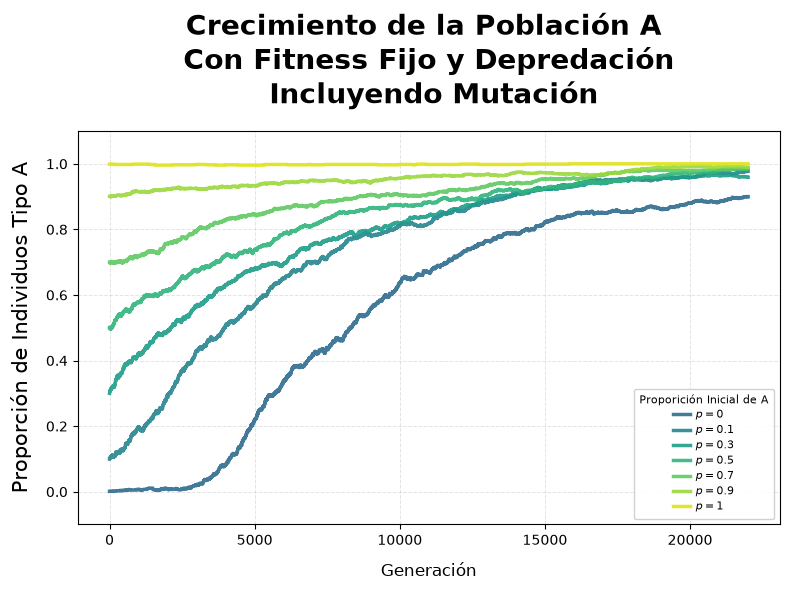

In [ ]:
plot(tamanio=(8, 6), p=[0,0.1,0.3,0.5,0.7,0.9,1], 
    legendname="Proporición Inicial de A", tittle="Crecimiento de la Población A \n Con Fitness Fijo y Depredación \n Incluyendo Mutación", 
     xlabel="Generación", ylabel="Proporción de Individuos Tipo A", save_name="PM_FitFijo_DepreFija_MPoisson",
       process_func=moranProcessFitnessDepredacion, N=1000, T=22000,g=0, poisson= True)

En este caso vemos que se fijará más rápidamente uno de los alelos lo que consiste en que el ruido ayuda a  facilitar las fijaciones.
Además, asumimos el caso dónde no morirá el grupo porque la comida siempre será suficiente no habrá competencia entre estos ni nada.

--- 

1. Tiempo de corrido del fitness landscape dada la grilla. 


In [ ]:
inicio = time.perf_counter()

X,Y,Z = DeltaW(np.linspace(0, 1, 1000),np.linspace(0, 1, 1000), deltaWFilas, 0)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_AA - W_AB",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_1",
    X=X,
    Y=Y,
    Z=Z
)   

fin = time.perf_counter()

tiempo_transcurrido1 = fin-inicio

inicio = time.perf_counter()

X,Y,Z = DeltaW(np.linspace(0, 1, 10000),np.linspace(0, 1, 10000), deltaWFilas, 0)

plotFL(
    tamanio=(850, 700),
    legendname="ΔW",
    tittle="Superficie de ΔW = W_AA - W_AB",
    xlabel="Densidad de Depredación(η_d)",
    ylabel="Densidad de Fenotipo A (p)",
    save_name="FL_Teorico_1",
    X=X,
    Y=Y,
    Z=Z
)   


fin = time.perf_counter()

tiempo_transcurrido2 = fin-inicio

print(f'Diferencia temporal {tiempo_transcurrido2/tiempo_transcurrido1}')